# Shortcut reliance in NLI: Logistic Regression vs. RoBERTa

TDT13 project

By: Malin Haugland Høli and Ina Martini

## The task

**Natural Language Inference (NLI)** is about deciding how two sentences relate. Given a **premise** and a **hypothesis**, the model must say whether the hypothesis is:

- **entailment:** definitely true if the premise is true
- **neutral:** might be true
- **contradiction:** definitely false if the premise is true

To do this properly, a model has to **compare the two sentences**. The same hypothesis can get different labels depending on the premise (made-up example):

| premise | hypothesis | label |
|---|---|---|
| "The man is sleeping." | "The man is not awake." | entailment |
| "The man is reading." | "The man is not awake." | contradiction |

## The problem: shortcuts

In NLI datasets such as MultiNLI, the hypotheses were written by crowdworkers, and the way they wrote them left patterns behind. For example, hypotheses containing *not* or *never* are often contradictions. A model can learn these patterns and guess the label **from the hypothesis alone, without reading the premise**. This often gives the right answer, but for the wrong reason, and it fails on examples like the first row above. Such patterns are called **annotation artifacts** or **shortcuts** (Gururangan et al., 2018; Poliak et al., 2018).

## Research question

Do a simple model (**TF-IDF + logistic regression**) and a large pretrained model (**RoBERTa-large fine-tuned on MultiNLI**) rely on the same word-level shortcuts, and do explanation methods (**SHAP**) show the same words driving both?

## Approach

1. **EDA:** find the shortcuts in the data, especially negation words.
2. **Logistic regression:** a simple model, including one that only sees the hypothesis. It shows how far the shortcuts alone can get.
3. **RoBERTa:** run the pretrained model with and without the premise. If removing the premise hurts it a lot, it really uses the premise.
4. **Results:** compare accuracy, especially on examples where the negation shortcut gives the wrong answer.
5. **SHAP:** compare which words each model's predictions depend on.

## 0. Config

In [ ]:
import os
import random
import re

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from matplotlib.patches import Patch
import scipy.sparse as sp
from functools import cache
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix
import json
from sklearn.model_selection import train_test_split


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RESULTS_DIR = "results"
FIGURES_DIR = "figures"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# Sentential negation: not/n't + negative indefinites (no-series) + neither/nor (Huddleston 2005; Haspelmath 1997; Kane 2021)
NEGATION_WORDS = {"no", "not", "never", "nobody", "nothing", "none", "nowhere", "n't", "cannot", "neither", "nor"}

Device: cpu


## 1. Data loading

### Dataset: MultiNLI

We use the **Multi-Genre Natural Language Inference (MultiNLI)** corpus (Williams et al., 2018), loaded from Hugging Face as `nyu-mll/multi_nli`. Each example is a **premise** sentence paired with a **hypothesis** sentence written by a crowdworker. The label says how the two relate:

- **entailment (0):** the hypothesis must be true if the premise is true
- **neutral (1):** the hypothesis might be true
- **contradiction (2):** the hypothesis cannot be true if the premise is true

Premises come from ten genres of written and spoken English. Five of them (fiction, government, slate, telephone, travel) are used for training. The corpus has two validation splits:

| Split | Size | Genres |
|---|---|---|
| `train` | ~393k | fiction, government, slate, telephone, travel |
| `validation_matched` | ~9.8k | **same** five genres as train (in-domain) |
| `validation_mismatched` | ~9.8k | five **unseen** genres: 9/11 report, face-to-face, letters, OUP, verbatim (out-of-domain) |

In [70]:
raw = load_dataset("nyu-mll/multi_nli")
raw

DatasetDict({
    train: Dataset({
        features: ['promptID', 'pairID', 'premise', 'premise_binary_parse', 'premise_parse', 'hypothesis', 'hypothesis_binary_parse', 'hypothesis_parse', 'genre', 'label'],
        num_rows: 392702
    })
    validation_matched: Dataset({
        features: ['promptID', 'pairID', 'premise', 'premise_binary_parse', 'premise_parse', 'hypothesis', 'hypothesis_binary_parse', 'hypothesis_parse', 'genre', 'label'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['promptID', 'pairID', 'premise', 'premise_binary_parse', 'premise_parse', 'hypothesis', 'hypothesis_binary_parse', 'hypothesis_parse', 'genre', 'label'],
        num_rows: 9832
    })
})

In [71]:
LABEL_NAMES = raw["train"].features["label"].names  # ['entailment', 'neutral', 'contradiction']
print(LABEL_NAMES)

cols = ["promptID", "premise", "hypothesis", "label", "genre"]  # promptID identifies the premise
train_df = raw["train"].to_pandas()[cols]
val_df = raw["validation_matched"].to_pandas()[cols]
val_mm_df = raw["validation_mismatched"].to_pandas()[cols]

for name, df in [("train", train_df), ("validation_matched", val_df), ("validation_mismatched", val_mm_df)]:
    print(f"{name:22s} {len(df):>7,} examples")

['entailment', 'neutral', 'contradiction']
train                  392,702 examples
validation_matched       9,815 examples
validation_mismatched    9,832 examples


In [72]:
train_df.sample(5, random_state=SEED).assign(label=lambda d: d.label.map(dict(enumerate(LABEL_NAMES))))

,promptID,premise,hypothesis,label,genre
155219,1185,That's all right.,That's fine.,entailment,fiction
327538,109910,Televisions are expensive these days.,Televisions cost $200 when you purchase them f...,neutral,slate
325456,126601,The colonial porte cochre sets the tone for Wa...,The colonial porte coche on the front of the p...,neutral,travel
341461,127136,and you just sift,"Don't sift, ever.",contradiction,telephone
54698,56618,You think there's somethin' in all that talk T...,Topham had supported the talk due to his own d...,neutral,fiction


## 2. Exploratory Data Analysis

### Label distribution

The training set is exactly balanced (one third per class), so a model gains nothing from favouring one label in general. Both validation splits are nearly balanced. Entailment is slightly over-represented (about 35%) and neutral slightly under (about 32%). 

In [73]:
print("Mean premise and hypothesis lengths (in words) for the training set:")
for col in ["premise", "hypothesis"]:
    print(f"Mean {col} length (words): {train_df[col].str.split().str.len().mean():.1f}")

# Label distribution per split (rows = splits, columns = labels), same layout as the negation table
label_dist = pd.DataFrame({
    "train": train_df.label.map(dict(enumerate(LABEL_NAMES))).value_counts(normalize=True),
    "validation_matched": val_df.label.map(dict(enumerate(LABEL_NAMES))).value_counts(normalize=True),
    "validation_mismatched": val_mm_df.label.map(dict(enumerate(LABEL_NAMES))).value_counts(normalize=True),
}).T.round(3)[LABEL_NAMES]
label_dist.columns.name = "label"
label_dist

Mean premise and hypothesis lengths (in words) for the training set:
Mean premise length (words): 19.8
Mean hypothesis length (words): 10.0


label,entailment,neutral,contradiction
train,0.333,0.333,0.333
validation_matched,0.354,0.318,0.327
validation_mismatched,0.352,0.318,0.330


### Negation in the hypothesis

For each split, we divide the hypotheses into two groups, with and without a negation word (`NEGATION_WORDS` or any *n't* contraction), and show the label shares in each group (`n` = number of examples).

22% of the train hypotheses contain negation. 58% of those are contradictions, against 26% of the hypotheses without negation. The validation splits show the same pattern (56% in `validation_matched`, 63% in `validation_mismatched`), so the cue is also present where the models are evaluated.

Negated hypotheses that are *not* contradictions are the **traps**: there, following the shortcut gives the wrong answer. `validation_matched` has 937 of them.

In [74]:
TOKEN_RE = re.compile(r"[\w']+")

def has_negation(text: str) -> bool:
    # Contractions (don't, isn't, can't, ...) count as negation via the "n't" suffix
    return any(tok in NEGATION_WORDS or tok.endswith("n't") for tok in TOKEN_RE.findall(text.lower()))

for df in (train_df, val_df, val_mm_df):
    df["hyp_neg"] = df.hypothesis.map(has_negation)

# The classic annotation artifact: label shares for hypotheses with vs. without negation, per split
rows = []
for name, df in [("train", train_df), ("validation_matched", val_df), ("validation_mismatched", val_mm_df)]:
    shares = pd.crosstab(df.hyp_neg, df.label.map(dict(enumerate(LABEL_NAMES))), normalize="index")[LABEL_NAMES]
    counts = df.hyp_neg.value_counts()
    for neg in (False, True):
        rows.append({"split": name, "hypothesis": "negation" if neg else "no negation",
                     "n": counts[neg], **shares.loc[neg].round(3)})
neg_by_split = pd.DataFrame(rows).set_index(["split", "hypothesis"])

# Negated hypotheses that are NOT contradictions are where the shortcut misleads (the traps)
neg_labels = val_df.label[val_df.hyp_neg].map(dict(enumerate(LABEL_NAMES))).value_counts()
print(f"validation_matched: {val_df.hyp_neg.sum():,} negated hypotheses, of which "
      f"{neg_labels.entailment + neg_labels.neutral:,} are traps "
      f"({neg_labels.entailment:,} entailment, {neg_labels.neutral:,} neutral)")
neg_by_split

validation_matched: 2,142 negated hypotheses, of which 937 are traps (496 entailment, 441 neutral)


n  entailment  neutral  contradiction
split                 hypothesis                                             
train                 no negation  305331       0.371    0.366          0.263
                      negation      87371       0.203    0.219          0.578
validation_matched    no negation    7673       0.389    0.350          0.262
                      negation       2142       0.232    0.206          0.563
validation_mismatched no negation    7688       0.398    0.355          0.246
                      negation       2144       0.187    0.185          0.629

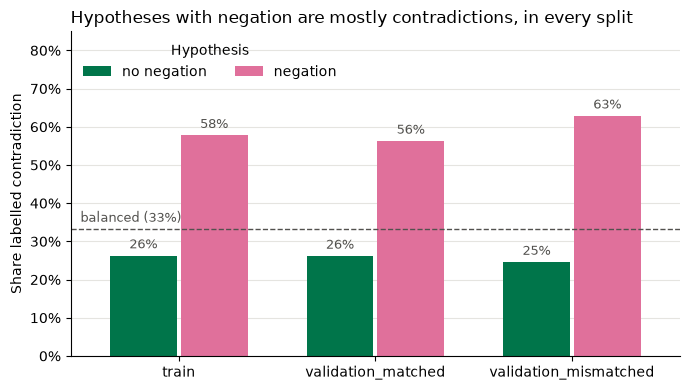

In [ ]:
# Share of contradictions with vs. without negation in the hypothesis, per split
contra = neg_by_split["contradiction"].unstack("hypothesis").loc[neg_by_split.index.unique("split")]
groups = [("no negation", "#00754a"), ("negation", "#e0709b")]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(contra))
width = 0.36
for i, (group, color) in enumerate(groups):
    bars = ax.bar(x + (i - 0.5) * width, contra[group], width - 0.02, color=color, label=group)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in contra[group]], padding=3, fontsize=9, color="#52514e")

ax.axhline(1 / 3, color="#52514e", linestyle="--", linewidth=1)
ax.text(-0.5, 1 / 3 + 0.01, "balanced (33%)", ha="left", va="bottom", fontsize=9, color="#52514e")

ax.set_xticks(x, contra.index)
ax.set_xlim(-0.55, len(contra) - 0.45)
ax.set_ylabel("Share labelled contradiction")
ax.set_ylim(0, 0.85)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("Hypotheses with negation are mostly contradictions, in every split", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(title="Hypothesis", frameon=False, loc="upper left", ncol=2)

fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "negation_contradiction_by_split.png"), dpi=200)
plt.show()

### Negation cue per word

Which negation words carry the cue? For each word in `NEGATION_WORDS`, we show how many train hypotheses contain it (`n`) and the label shares among them, sorted by the contradiction share.
"never", "none" and "nothing" are strong cues of contradiction

In [76]:
def negation_words_in(text: str) -> set:
    # All contractions (don't, isn't, ...) are grouped as "n't"
    toks = TOKEN_RE.findall(text.lower())
    return {"n't" if tok.endswith("n't") else tok for tok in toks if tok in NEGATION_WORDS or tok.endswith("n't")}

# A hypothesis with several negation words counts once for each of them
neg_words = (pd.DataFrame({"word": train_df.hypothesis.map(negation_words_in),
                           "label": train_df.label.map(dict(enumerate(LABEL_NAMES)))})
             .explode("word", ignore_index=True).dropna())

print(f"Number of negation words in the training set: {len(neg_words):,}")
word_table = pd.crosstab(neg_words.word, neg_words.label, normalize="index").round(3)[LABEL_NAMES]
word_table.insert(0, "n", neg_words.word.value_counts())
word_table.sort_values("contradiction", ascending=False)

Number of negation words in the training set: 90,269


label,n,entailment,neutral,contradiction
word,,,,
never,8297,0.073,0.139,0.788
none,702,0.090,0.123,0.788
nothing,2741,0.115,0.128,0.758
no,16369,0.115,0.129,0.756
nowhere,192,0.115,0.130,0.755
nor,241,0.166,0.100,0.734
nobody,866,0.104,0.201,0.695
neither,245,0.204,0.127,0.669
cannot,1336,0.201,0.217,0.582


### Most label-revealing hypothesis words

Negation is not the only cue. For every word that appears in at least 500 train hypotheses (`MIN_DF`), we compute the share of those hypotheses that have each label. Since train is balanced, any share well above 0.333 means the word alone gives the label away. The table shows the top words per label, with the share and the number of hypotheses containing the word (`n`) in parentheses.

In [ ]:
TOP_K = 10
MIN_DF = 500  # a word must appear in at least this many train hypotheses

# Binary bag of words over train hypotheses, same tokenization as has_negation; min_df drops rare, noisy words
vec = CountVectorizer(token_pattern=r"[\w']+", binary=True, min_df=MIN_DF)
X = vec.fit_transform(train_df.hypothesis)
Y = np.eye(len(LABEL_NAMES))[train_df.label]  # one-hot labels

word_label = np.asarray(X.T @ Y)  # number of hypotheses containing each word, per label
word_n = pd.Series(word_label.sum(1).astype(int), index=vec.get_feature_names_out())
share = pd.DataFrame(word_label / word_label.sum(1, keepdims=True),
                     index=vec.get_feature_names_out(), columns=LABEL_NAMES)
print(f"{len(share):,} words appear in at least {MIN_DF} train hypotheses")
print("Top words per label: share of hypotheses with that label (n = hypotheses containing the word)")

top_words = pd.DataFrame({
    label: [f"{w} ({share.at[w, label]:.2f}, n={word_n[w]:,})" for w in share[label].nlargest(TOP_K).index]
    for label in LABEL_NAMES
})
top_words

901 words appear in at least 500 train hypotheses
Top words per label: share of hypotheses with that label (n = hypotheses containing the word)


,entailment,neutral,contradiction
0,"yes (0.53, n=1,199)","also (0.68, n=2,717)","never (0.79, n=8,297)"
1,"aware (0.51, n=521)","because (0.61, n=9,054)","none (0.79, n=702)"
2,"sometimes (0.50, n=888)","battle (0.60, n=567)","nothing (0.76, n=2,741)"
3,"some (0.50, n=6,292)","popular (0.59, n=1,647)","no (0.76, n=16,369)"
4,"according (0.48, n=975)","tourists (0.59, n=940)","hate (0.72, n=640)"
5,"called (0.48, n=1,195)","due (0.57, n=1,746)","completely (0.72, n=1,190)"
6,"something (0.48, n=2,810)","prefer (0.57, n=500)","any (0.70, n=7,654)"
7,"bit (0.47, n=535)","liked (0.56, n=514)","nobody (0.70, n=866)"
8,"multiple (0.47, n=561)","better (0.55, n=2,781)","anything (0.67, n=3,319)"
9,"may (0.46, n=2,621)","wanted (0.55, n=2,436)","stayed (0.67, n=578)"


### Examples per genre

Train and `validation_matched` share the same five genres, while `validation_mismatched` contains five genres that never appear in training. Within each split the genres are close to equally sized (about 20% each). Telephone is slightly larger in train (83k vs. about 77k for the others).

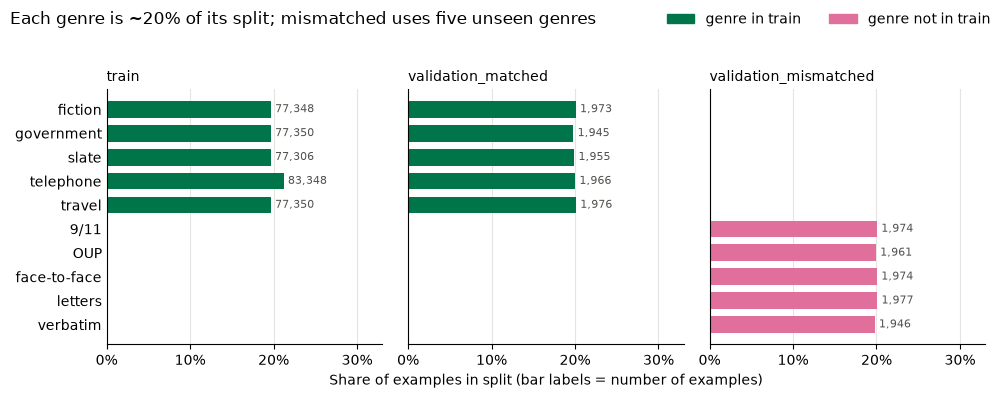

In [ ]:
GENRE_NAMES = {"facetoface": "face-to-face", "nineeleven": "9/11", "oup": "OUP"}
splits = [("train", train_df), ("validation_matched", val_df), ("validation_mismatched", val_mm_df)]
genre_counts = pd.DataFrame({name: df.genre.value_counts() for name, df in splits}).fillna(0).astype(int)
genre_counts.index = genre_counts.index.map(lambda g: GENRE_NAMES.get(g, g))
train_genres = set(genre_counts.index[genre_counts["train"] > 0])
# Training genres first, then the unseen (mismatched) genres
genre_counts = genre_counts.loc[sorted(genre_counts.index, key=lambda g: (g not in train_genres, g))]

# Share of each split per genre, so the large train split and the small validation splits share one scale
genre_share = genre_counts / genre_counts.sum()
colors = ["#00754a" if g in train_genres else "#e0709b" for g in genre_counts.index]

fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharey=True, sharex=True)
for ax, split in zip(axes, genre_counts.columns):
    bars = ax.barh(genre_counts.index, genre_share[split], color=colors, height=0.7)
    ax.bar_label(bars, labels=[f"{n:,}" if n else "" for n in genre_counts[split]],
                 padding=3, fontsize=8, color="#52514e")
    ax.set_title(split, fontsize=10, loc="left")
    ax.set_xlim(0, 0.33)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
axes[0].invert_yaxis()
axes[1].set_xlabel("Share of examples in split (bar labels = number of examples)")

fig.legend(handles=[Patch(color="#00754a", label="genre in train"), Patch(color="#e0709b", label="genre not in train")],
           frameon=False, loc="upper right", ncol=2)
fig.suptitle("Each genre is ~20% of its split; mismatched uses five unseen genres", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(os.path.join(FIGURES_DIR, "examples_per_genre.png"), dpi=200)
plt.show()

## 3. Logistic Regression

We train two TF-IDF + logistic regression models on `train`:

- **LR-full** sees both premise and hypothesis.
- **LR-hyp** sees only the hypothesis. This is the hypothesis-only baseline (Gururangan et al., 2018; Poliak et al., 2018): if it beats the majority baseline, the hypotheses alone contain label cues.

Premise and hypothesis get **separate vectorizers**, so every feature is either `P:word` or `H:word`. That lets us see later how much each model relies on the premise versus the hypothesis. We use unigrams and bigrams, the same tokenization as in the EDA, and **no stopword removal**, since stopword lists delete "not" and "no".

A "feature" represents an ngram-token, e.g. "i am", "awake", and "am awake". Since each premise is used three times in the training dataset, we use **min_df = 4** to make sure each feature is represented in more than 1 premise. For hypthesises we use **min_df = 2**

In [ ]:
def make_vectorizer(min_df=2):
    # Same tokenization as TOKEN_RE (keeps "not", "don't" and one-letter words), unigrams + bigrams, no stopword removal
    return TfidfVectorizer(token_pattern=TOKEN_RE.pattern, ngram_range=(1, 2), min_df=min_df, sublinear_tf=True)

vec_p, vec_h = make_vectorizer(min_df=4), make_vectorizer()
Xp_train = vec_p.fit_transform(train_df.premise)
Xh_train = vec_h.fit_transform(train_df.hypothesis)
N_P = Xp_train.shape[1]  # premise features come first, hypothesis features after

def featurize(df):
    return sp.hstack([vec_p.transform(df.premise), vec_h.transform(df.hypothesis)]).tocsr()

X_train = sp.hstack([Xp_train, Xh_train]).tocsr()
X_val, X_val_mm = featurize(val_df), featurize(val_mm_df)
y_train, y_val, y_val_mm = train_df.label.values, val_df.label.values, val_mm_df.label.values

feature_names = np.concatenate([["P:" + w for w in vec_p.get_feature_names_out()],
                                ["H:" + w for w in vec_h.get_feature_names_out()]])
print(f"Premise features: {N_P:,}   Hypothesis features: {X_train.shape[1] - N_P:,}")

Premise features: 266,453   Hypothesis features: 356,400


### Training LR-full and LR-hyp

We choose the regularisation strength `C` from {0.1, 1, 10} on a held-out 10% of train, split by premise, then refit on all of train with the best `C`. The reasoning is explained below the cell.

In [85]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GroupShuffleSplit

C_GRID = [0.1, 1, 10]
ALL_COLS = slice(None)
HYP_COLS = slice(N_P, None)  # LR-hyp only sees the hypothesis features

# Held-out 10% of train for choosing C, split by premise (promptID). Each premise appears three times,
# once per label, so a random split would put the same premise on both sides and make held-out accuracy misleading.
idx_fit, idx_dev = next(GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
                        .split(X_train, y_train, groups=train_df.promptID))
X_fit, X_dev = X_train[idx_fit], X_train[idx_dev]

def tune_C(cols):
    scores = {}
    for C in C_GRID:
        model = LogisticRegression(C=C, max_iter=1000).fit(X_fit[:, cols], y_train[idx_fit])
        scores[C] = accuracy_score(y_train[idx_dev], model.predict(X_dev[:, cols]))
        print(f"  C={C:<4} held-out accuracy {scores[C]:.4f}")
    return max(scores, key=scores.get)

def fit_or_load(name, cols):
    # Training takes several minutes, so the final model is cached. Delete the file if the features change.
    path = os.path.join(RESULTS_DIR, f"{name}.pkl")
    if os.path.exists(path):
        print(f"{name}: loaded from {path}")
        return joblib.load(path)
    print(f"{name}: tuning C")
    best_C = tune_C(cols)
    print(f"{name}: best C = {best_C}, refitting on all of train")
    model = LogisticRegression(C=best_C, max_iter=1000).fit(X_train[:, cols], y_train)
    joblib.dump(model, path)
    return model

lr_full = fit_or_load("lr_full_min4", ALL_COLS)
lr_hyp = fit_or_load("lr_hyp_min4", HYP_COLS)

lr_full_min4: loaded from results\lr_full_min4.pkl
lr_hyp_min4: loaded from results\lr_hyp_min4.pkl


c:\NTNU\H26\TDT13\nli-project-tdt13\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


**Why a held-out set, and why split it by premise?**

Logistic regression has one setting we choose ourselves: `C`, which decides how closely the model fits the training data. To pick the best `C`, we need to test each version on examples the model has *not* seen during training. We cannot use the training data (the model has seen those answers), and we should not use `validation_matched`, since that is the set we report in the final results. So we hide 10% of the training data while training. This **held-out** set is used only to choose `C`. The held-out accuracies are printed by the cell above.

The hidden part has to contain **whole premises**. In MultiNLI each premise was used three times, once per label (made-up example):

| premise | hypothesis | label |
|---|---|---|
| "The man is playing guitar." | "Someone is making music." | entailment |
| "The man is playing guitar." | "He is in a famous band." | neutral |
| "The man is playing guitar." | "The man is sleeping." | contradiction |

If we hide 10% of the rows at random, the model may train on the first two rows and be tested on the third. It then learns "*guitar* in the premise → entailment or neutral" and gets the hidden contradiction wrong. That is an unfair test. Splitting **by premise** (`promptID`) hides either all three rows of a premise or none, so the held-out premises are new, just like in the real validation set.

The check below shows the difference. A fair held-out set should give about the same accuracy as `validation_matched`, which has truly new premises. With a random split, held-out accuracy is much lower than validation accuracy, so it does not reflect how the model really performs. With the split by premise, the two are close.

**Result:** `C = 1` is best for both models (held-out accuracy 0.561 for LR-full, 0.549 for LR-hyp).

In [137]:
# Check: train LR-full (C=1) on a random split and on the premise-grouped split, and compare the held-out
# accuracy with accuracy on validation_matched.
path = os.path.join(RESULTS_DIR, "split_check.json")
if os.path.exists(path):
    split_check = json.load(open(path))
else:
    idx_fit_rand, idx_dev_rand = train_test_split(np.arange(len(y_train)), test_size=0.1, random_state=SEED)
    split_check = {}
    for split_name, (fit, dev) in [("random", (idx_fit_rand, idx_dev_rand)), ("by premise", (idx_fit, idx_dev))]:
        model = LogisticRegression(C=1, max_iter=1000).fit(X_train[fit], y_train[fit])
        split_check[split_name] = {"held-out accuracy": accuracy_score(y_train[dev], model.predict(X_train[dev])),
                                   "validation_matched accuracy": accuracy_score(y_val, model.predict(X_val))}
    json.dump(split_check, open(path, "w"), indent=2)

pd.DataFrame(split_check).T.round(3).rename_axis("held-out split")

,held-out accuracy,validation_matched accuracy
held-out split,,
random,0.406,0.558
by premise,0.561,0.560


### Validation results

A first check of both models on the two validation splits, next to the majority-class baseline. The full comparison with RoBERTa and the premise-removed conditions comes in the results section.

In [87]:
from sklearn.metrics import f1_score

def evaluate(model, X, y):
    pred = model.predict(X)
    return {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro")}

rows = []
for split, X_split, y_split in [("validation_matched", X_val, y_val), ("validation_mismatched", X_val_mm, y_val_mm)]:
    # Train is balanced, so the baseline always predicts the most frequent label of the split (entailment)
    majority = np.full_like(y_split, np.bincount(y_split).argmax())
    rows.append({"model": "majority class", "split": split,
                 "accuracy": accuracy_score(y_split, majority), "macro_f1": f1_score(y_split, majority, average="macro")})
    rows.append({"model": "LR-full", "split": split, **evaluate(lr_full, X_split, y_split)})
    rows.append({"model": "LR-hyp", "split": split, **evaluate(lr_hyp, X_split[:, HYP_COLS], y_split)})

pd.DataFrame(rows).pivot(index="model", columns="split", values=["accuracy", "macro_f1"]).round(3)

accuracy                                 macro_f1  \
split          validation_matched validation_mismatched validation_matched   
model                                                                        
LR-full                     0.558                 0.552              0.559   
LR-hyp                      0.543                 0.539              0.544   
majority class              0.354                 0.352              0.174   

                                      
split          validation_mismatched  
model                                 
LR-full                        0.553  
LR-hyp                         0.541  
majority class                 0.174

**Interpretation.**

**How to read the table:** accuracy is the share of examples the model labels correctly. Macro-F1 is a similar score that checks all three labels are handled well, not just the most common one. The **majority class** row is a "dumb" baseline that always answers *entailment*. It gets 35% right just because 35% of the validation examples are entailment.

**1. The hypothesis alone is enough to get far above the baseline.**
LR-hyp never sees the premise, yet it gets 54% right, compared with 35% for the baseline. Without the premise it is impossible to know whether the hypothesis follows from it, so the model cannot be doing real reasoning. Instead it recognises patterns in how the hypotheses were written, such as "contains *never* → probably contradiction". These are the shortcuts (annotation artifacts) we saw in the EDA. Earlier work found the same (Gururangan et al., 2018; Poliak et al., 2018).

**2. Giving the model the premise as well barely helps.**
LR-full sees both sentences but only gets 56%, just 1 point more than LR-hyp. The reason is that logistic regression looks at each word on its own. It cannot compare the two sentences, for example notice that "dog" in the premise matches "animal" in the hypothesis. So in practice LR-full relies on the same hypothesis shortcuts as LR-hyp. That makes it a useful "shortcut-only" reference to compare RoBERTa against.

**3. The results are the same on familiar and unfamiliar genres** (matched vs. mismatched). The shortcuts come from how people wrote the hypotheses, not from the topic of the text, so they work just as well on new genres.

**4. Macro-F1 is about the same as accuracy**, so the models handle all three labels about equally well. The baseline's macro-F1 is very low (0.17), because it only ever answers one of the three labels.

**What we expect next:** since LR-full hardly uses the premise, removing the premise at test time should barely change its score. If RoBERTa's score drops a lot without the premise, that shows RoBERTa really does use it.

### Top coefficients of LR-full

The features with the largest positive coefficient for each label, i.e. the words that push LR-full most towards that label. `P:` features come from the premise, `H:` from the hypothesis.

In [88]:
TOP_N = 20
coef = lr_full.coef_  # shape (3, n_features), rows follow LABEL_NAMES

print(f"Top {TOP_N} LR-full features per label (coefficient in parentheses):")
for i, label in enumerate(LABEL_NAMES):
    top = np.argsort(coef[i])[::-1][:TOP_N]
    n_hyp = sum(feature_names[j].startswith("H:") for j in top)
    print(f"  {label:13s} {n_hyp}/{TOP_N} hypothesis features, {TOP_N - n_hyp}/{TOP_N} premise features")

top_coefs = pd.DataFrame({
    label: [f"{feature_names[j]} ({coef[i, j]:.2f})" for j in np.argsort(coef[i])[::-1][:TOP_N]]
    for i, label in enumerate(LABEL_NAMES)
})
top_coefs

Top 20 LR-full features per label (coefficient in parentheses):
  entailment    20/20 hypothesis features, 0/20 premise features
  neutral       20/20 hypothesis features, 0/20 premise features
  contradiction 20/20 hypothesis features, 0/20 premise features


,entailment,neutral,contradiction
0,H:not always (4.30),H:because (7.36),H:never (11.19)
1,H:some (3.21),H:also (6.43),H:no (10.90)
2,H:there is (2.48),H:the (5.94),H:nothing (7.05)
3,H:there was (2.45),H:many (5.01),H:nobody (5.87)
4,H:there are (2.32),H:said the (4.49),H:are no (5.87)
5,H:not easy (2.29),H:most (4.35),H:only (5.81)
6,H:than one (2.29),H:but (4.31),H:any (5.58)
7,H:no longer (2.22),H:other (3.90),H:not (4.89)
8,H:not bad (2.10),H:to (3.86),H:none (4.63)
9,H:is possible (1.98),H:enjoyed (3.74),H:all (4.50)


**Interpretation.**

**How to read the table:** each column lists the 20 words (or word pairs) that push LR-full most strongly towards that label. The number is the coefficient: the bigger it is, the stronger the push. `H:` means the word is in the hypothesis, `P:` that it is in the premise.

**1. The model looks almost only at the hypothesis.** All 60 words come from the hypothesis (`H:`). This confirms what the accuracy table suggested: the model mostly ignores the premise.

**2. The words are the same shortcuts we found in the EDA.**
- **Contradiction:** negation words (*never, no, nothing, nobody, not, didn't, don't*) and strong, absolute words (*completely, perfectly, only, all, hate, refused*). Writers often made a contradiction by negating or exaggerating the premise.
- **Neutral:** words that add something new, like a reason or extra detail (*because, also, besides*), and opinions (*enjoyed, better, popular*). Writers often made a neutral hypothesis by adding information the premise does not mention.
- **Entailment:** careful, vague words (*some, may, sometimes*). Writers often made an entailment by saying something less specific than the premise, which is then safely true.

**3. Strong and weak negation words, as in the EDA.** *never* (11.2) and *no* (10.9) push more than twice as hard towards contradiction as *not* (4.9). The EDA showed the same: *never* and *no* are much more reliable signs of contradiction than *not*.

**4. A small exception: softened negations point to entailment.** Word pairs such as "not always", "not bad" and "no longer" are in the entailment column. Because the model also looks at pairs of words, it has learned that these particular phrases do not mean contradiction. It has only learned this for these exact phrases, though, not in general.

**A caution:** do not compare the numbers too exactly. Very common words like *the* can get big numbers without actually mattering much. The SHAP analysis later measures more precisely how much each word affects the predictions.

## 4. RoBERTa inference

We use `roberta-large-mnli`: RoBERTa-large (Liu et al., 2019) that its authors already fine-tuned on the MultiNLI training set. We do not train it ourselves, we only run it.

We run it on both validation splits with two kinds of input:

- **full:** premise and hypothesis, the normal task
- **no premise:** the premise is replaced by an empty string, so the model only sees the hypothesis

If RoBERTa really uses the premise, its accuracy should drop a lot without it. If it mostly relies on hypothesis shortcuts, like logistic regression, the drop will be small. One caveat: the model never saw an empty premise during training, so part of any drop may come from the unusual input itself.

Two technical details:

- **Label order:** the model numbers the labels the other way round from the dataset (0 = contradiction instead of 0 = entailment). The code reorders the model's outputs so they follow `LABEL_NAMES`, and the check below confirms this.
- **Caching:** the outputs (logits, one score per label) are saved to `results/roberta_*.npy`. Once these files exist, the cells load them instead of running the model.

In [ ]:
ROBERTA_NAME = "FacebookAI/roberta-large-mnli"
BATCH_SIZE = 64

@cache
def load_roberta():
    # Only called when a result is not cached yet, so a laptop with cached results never downloads the model
    tokenizer = AutoTokenizer.from_pretrained(ROBERTA_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(ROBERTA_NAME).to(DEVICE).eval()
    if DEVICE == "cuda":
        model = model.half()  # 16-bit floats: about twice as fast on a GPU, same predictions in practice
    return tokenizer, model

@torch.no_grad()
def roberta_logits(premises, hypotheses, progress=True):
    tokenizer, model = load_roberta()
    batches = []
    for i in tqdm(range(0, len(premises), BATCH_SIZE), disable=not progress):
        enc = tokenizer(premises[i:i + BATCH_SIZE], hypotheses[i:i + BATCH_SIZE],
                        padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEVICE)
        batches.append(model(**enc).logits.float().cpu().numpy())
    logits = np.concatenate(batches)
    # The model's label order (CONTRADICTION, NEUTRAL, ENTAILMENT) is the reverse of the dataset's,
    # so reorder the columns to follow LABEL_NAMES
    order = [model.config.label2id[name.upper()] for name in LABEL_NAMES]
    return logits[:, order]

def cached_roberta_logits(name, premises, hypotheses):
    path = os.path.join(RESULTS_DIR, f"roberta_{name}.npy")
    if os.path.exists(path):
        print(f"roberta_{name}: loaded from {path}")
        return np.load(path)
    print(f"roberta_{name}: running the model")
    logits = roberta_logits(premises, hypotheses)
    np.save(path, logits)
    return logits

In [90]:
# Logits for both validation splits, with the full input and with the premise removed (empty string)
roberta_logits_by = {}
for split, df in [("validation_matched", val_df), ("validation_mismatched", val_mm_df)]:
    hypotheses = df.hypothesis.tolist()
    roberta_logits_by[(split, "full")] = cached_roberta_logits(f"{split}_full", df.premise.tolist(), hypotheses)
    roberta_logits_by[(split, "no premise")] = cached_roberta_logits(f"{split}_no_premise", [""] * len(df), hypotheses)

roberta_validation_matched_full: loaded from results\roberta_validation_matched_full.npy
roberta_validation_matched_no_premise: loaded from results\roberta_validation_matched_no_premise.npy
roberta_validation_mismatched_full: loaded from results\roberta_validation_mismatched_full.npy
roberta_validation_mismatched_no_premise: loaded from results\roberta_validation_mismatched_no_premise.npy


### First check of the RoBERTa results

Accuracy and macro-F1 for both inputs on both validation splits. With the full input, accuracy on `validation_matched` should be about 0.90, the published result for this model. If it is about 0.30 instead, the label order is mixed up. The cell stops with an error in that case.

In [91]:
from sklearn.metrics import accuracy_score, f1_score

labels_by_split = {"validation_matched": val_df.label.values, "validation_mismatched": val_mm_df.label.values}
rows = []
for (split, condition), logits in roberta_logits_by.items():
    pred = logits.argmax(axis=1)
    rows.append({"input": condition, "split": split,
                 "accuracy": accuracy_score(labels_by_split[split], pred),
                 "macro_f1": f1_score(labels_by_split[split], pred, average="macro")})
roberta_scores = pd.DataFrame(rows).pivot(index="input", columns="split", values=["accuracy", "macro_f1"]).round(3)

# Sanity check of the label mapping: about 0.90 is expected, about 0.30 would mean the labels are mixed up
assert roberta_scores.loc["full", ("accuracy", "validation_matched")] > 0.8, "Accuracy too low: check the label mapping"
roberta_scores

accuracy                                 macro_f1  \
split      validation_matched validation_mismatched validation_matched   
input                                                                    
full                    0.906                 0.901              0.905   
no premise              0.371                 0.380              0.266   

                                  
split      validation_mismatched  
input                             
full                       0.900  
no premise                 0.281

**Interpretation.**

- **With the full input, RoBERTa does the task well:** 0.906 on `validation_matched` and 0.901 on `validation_mismatched`, matching the published result (so the label order is correct). Compare this with 0.558 for LR-full. Macro-F1 is about the same as accuracy, so all three labels are handled well.
- **Without the premise, accuracy drops to about 0.37,** even lower than LR-hyp (0.543). Macro-F1 drops even more (0.27), which means the model now handles the three labels very unevenly. The cells below show why.

### What does RoBERTa predict without the premise?

Accuracy alone does not say *what* the model answers. Here we count how often RoBERTa predicts each label, with and without the premise.

In [92]:
# Share of each predicted label on validation_matched, next to the shares of the true labels
pred_shares = {"True labels": np.bincount(val_df.label, minlength=len(LABEL_NAMES)) / len(val_df)}
for condition in ["full", "no premise"]:
    pred = roberta_logits_by[("validation_matched", condition)].argmax(axis=1)
    pred_shares[f"RoBERTa, {condition}"] = np.bincount(pred, minlength=len(LABEL_NAMES)) / len(pred)
print("Share of each label on validation_matched:")
pd.DataFrame(pred_shares, index=LABEL_NAMES).T.round(3)

Share of each label on validation_matched:


,entailment,neutral,contradiction
True labels,0.354,0.318,0.327
"RoBERTa, full",0.356,0.312,0.332
"RoBERTa, no premise",0.005,0.928,0.067


**Interpretation.** With the full input, RoBERTa predicts the three labels in about the same proportions as the true labels. Without the premise it answers **neutral 93% of the time**. That explains the low accuracy (0.37): the model does not break, it mostly refuses to guess. This is a sensible reaction, since without a premise you cannot know whether the hypothesis is true, and "might be true" is the honest answer.

This is the opposite of logistic regression. LR-hyp gets 0.543 without the premise by guessing from shortcuts, while RoBERTa's accuracy falls almost to the share of neutral examples (0.32). So RoBERTa depends heavily on the premise, which is what we would hope for in a model that really compares the two sentences.

### Does RoBERTa use the negation shortcut?

We split `validation_matched` by whether the hypothesis contains a negation word (as in the EDA) and look at how often RoBERTa answers contradiction, with and without the premise. This cell needs the `hyp_neg` column from the EDA section.

In [93]:
CONTRA = LABEL_NAMES.index("contradiction")
y = val_df.label.values
hyp_neg = val_df.hyp_neg.values  # computed in the EDA section

groups = {"no negation": ~hyp_neg,
          "negation": hyp_neg,
          "negation, not a contradiction (trap)": hyp_neg & (y != CONTRA)}
rows = []
for condition in ["full", "no premise"]:
    pred = roberta_logits_by[("validation_matched", condition)].argmax(axis=1)
    for group, mask in groups.items():
        rows.append({"input": condition, "hypothesis": group, "n": mask.sum(),
                     "accuracy": (pred[mask] == y[mask]).mean(),
                     "predicted contradiction": (pred[mask] == CONTRA).mean(),
                     "true contradiction": (y[mask] == CONTRA).mean()})
print("RoBERTa on validation_matched, by negation in the hypothesis:")
pd.DataFrame(rows).set_index(["input", "hypothesis"]).round(3)

RoBERTa on validation_matched, by negation in the hypothesis:


n  accuracy  \
input      hypothesis                                             
full       no negation                           7673     0.902   
           negation                              2142     0.922   
           negation, not a contradiction (trap)   937     0.859   
no premise no negation                           7673     0.368   
           negation                              2142     0.382   
           negation, not a contradiction (trap)   937     0.456   

                                                 predicted contradiction  \
input      hypothesis                                                      
full       no negation                                             0.264   
           negation                                                0.576   
           negation, not a contradiction (trap)                    0.067   
no premise no negation                                             0.028   
           negation                                                0.207   
           negation, not a contradiction (trap)                    0.055   

                                                 true contradiction  
input      hypothesis                                                
full       no negation                                        0.262  
           negation                                           0.563  
           negation, not a contradiction (trap)               0.000  
no premise no negation                                        0.262  
           negation                                           0.563  
           negation, not a contradiction (trap)               0.000

**Interpretation.**

**How to read the table:** the rows split the hypotheses into those without negation, those with negation, and the negated hypotheses that are *not* contradictions (the "traps", where the shortcut gives the wrong answer). "predicted contradiction" is how often RoBERTa answers contradiction, and "true contradiction" how often that is the true answer.

**1. With the premise, RoBERTa is not fooled by negation.** On the traps it gets 86% right, and it wrongly answers contradiction for only about 7% of them. When the premise is available, RoBERTa reads it instead of reacting to *not* or *never*.

**2. Without the premise, the shortcut shows up.** For hypotheses without negation, RoBERTa almost never answers contradiction (about 3%). For hypotheses with negation it does so about 21% of the time, roughly 7 times as often. So RoBERTa *has* learned the same "negation → contradiction" link as logistic regression. It is just a weak signal that only becomes visible when the premise is missing. With the premise, the premise wins.

**Conclusion so far:** both models have learned the negation shortcut, but they use it very differently. Logistic regression relies on it as a main strategy. For RoBERTa it is only a weak background signal, and it mainly decides by comparing the premise and the hypothesis. The results section compares both models on these same groups.

**Caveat:** RoBERTa never saw an empty premise during training. Part of the accuracy drop, and the strong preference for neutral, may therefore come from the unusual input itself, not only from the model "needing" the premise. This is a limitation of the premise-removal test.

## 5. Results: logistic regression vs. RoBERTa

Here we put both models side by side, using the cached LR models and RoBERTa outputs, so this section runs in seconds. It needs sections 0–4 to have been run first.

First we collect the predictions of every model and input on both validation splits. We also run LR-full **without the premise**, the same test we did for RoBERTa.

In [94]:
CONTRA = LABEL_NAMES.index("contradiction")

def all_predictions(split, df, X):
    # LR-full without the premise: empty premises give all-zero premise features
    X_no_premise = featurize(df.assign(premise=""))
    return {
        "majority class": np.full(len(df), np.bincount(df.label).argmax()),
        "LR-hyp": lr_hyp.predict(X[:, HYP_COLS]),
        "LR-full": lr_full.predict(X),
        "LR-full, no premise": lr_full.predict(X_no_premise),
        "RoBERTa": roberta_logits_by[(split, "full")].argmax(axis=1),
        "RoBERTa, no premise": roberta_logits_by[(split, "no premise")].argmax(axis=1),
    }

preds = {"validation_matched": all_predictions("validation_matched", val_df, X_val),
         "validation_mismatched": all_predictions("validation_mismatched", val_mm_df, X_val_mm)}

### Main results table

Accuracy and macro-F1 for all models and inputs on both validation splits.

In [95]:
rows = []
for split, df in [("validation_matched", val_df), ("validation_mismatched", val_mm_df)]:
    for model, pred in preds[split].items():
        rows.append({"model": model, "split": split, "accuracy": accuracy_score(df.label, pred),
                     "macro_f1": f1_score(df.label, pred, average="macro")})
main_results = (pd.DataFrame(rows)
                .pivot(index="model", columns="split", values=["accuracy", "macro_f1"])
                .loc[list(preds["validation_matched"])]  # keep the model order
                .round(3))
main_results

accuracy                        \
split               validation_matched validation_mismatched   
model                                                          
majority class                   0.354                 0.352   
LR-hyp                           0.543                 0.539   
LR-full                          0.558                 0.552   
LR-full, no premise              0.525                 0.511   
RoBERTa                          0.906                 0.901   
RoBERTa, no premise              0.371                 0.380   

                              macro_f1                        
split               validation_matched validation_mismatched  
model                                                         
majority class                   0.174                 0.174  
LR-hyp                           0.544                 0.541  
LR-full                          0.559                 0.553  
LR-full, no premise              0.521                 0.503  
RoBERTa                          0.905                 0.900  
RoBERTa, no premise              0.266                 0.281

**Interpretation.**

**How to read the table:** "no premise" means the premise was replaced by an empty string at test time, for a model that was trained *with* premises. LR-hyp is different: it was *trained* without premises.

1. **RoBERTa is far better at the task:** 0.906 vs. 0.558 for LR-full.
2. **Removing the premise is the key test.** LR-full drops from 0.558 to 0.525 (−3.3 points), RoBERTa from 0.906 to 0.371 (−53 points). Logistic regression barely uses the premise, RoBERTa depends on it.
3. **LR-full without the premise (0.525) is slightly worse than LR-hyp (0.543).** LR-hyp was trained to work without a premise, LR-full was not. The two measure different things: LR-hyp shows how much the *data* allows without the premise, the no-premise test shows how much a particular *model* uses it.
4. **RoBERTa without the premise is worse than LR-hyp,** but only because it answers neutral almost every time (see section 4), which also explains its low macro-F1 (0.27).
5. **`validation_mismatched` shows the same pattern,** so the conclusions hold for unseen genres too.

### The negation shortcut in both models

We split `validation_matched` into hypotheses without negation, with negation, and the **traps**: negated hypotheses that are *not* contradictions, where the shortcut gives the wrong answer (937 examples). For each model we show accuracy and how often it answers contradiction. A model that follows the shortcut answers contradiction too often for negated hypotheses and does badly on the traps.

In [96]:
y, hyp_neg = val_df.label.values, val_df.hyp_neg.values
groups = {"no negation": ~hyp_neg, "negation": hyp_neg, "trap": hyp_neg & (y != CONTRA)}
print("True share of contradictions:", ", ".join(f"{g} {(y[m] == CONTRA).mean():.0%}" for g, m in groups.items()))

model_order = [m for m in preds["validation_matched"] if m != "majority class"]
rows = []
for model in model_order:
    pred = preds["validation_matched"][model]
    for group, mask in groups.items():
        rows.append({"model": model, "hypothesis": group,
                     "accuracy": (pred[mask] == y[mask]).mean(),
                     "predicted contradiction": (pred[mask] == CONTRA).mean()})
(pd.DataFrame(rows)
   .pivot(index="model", columns="hypothesis", values=["accuracy", "predicted contradiction"])
   .reindex(columns=list(groups), level="hypothesis")
   .loc[model_order]
   .round(3))

True share of contradictions: no negation 26%, negation 56%, trap 0%


accuracy                 predicted contradiction  \
hypothesis          no negation negation   trap             no negation   
model                                                                     
LR-hyp                    0.522    0.617  0.292                   0.193   
LR-full                   0.536    0.638  0.333                   0.194   
LR-full, no premise       0.504    0.599  0.335                   0.121   
RoBERTa                   0.902    0.922  0.859                   0.264   
RoBERTa, no premise       0.368    0.382  0.456                   0.028   

                                     
hypothesis          negation   trap  
model                                
LR-hyp                 0.725  0.539  
LR-full                0.708  0.492  
LR-full, no premise    0.641  0.433  
RoBERTa                0.576  0.067  
RoBERTa, no premise    0.207  0.055

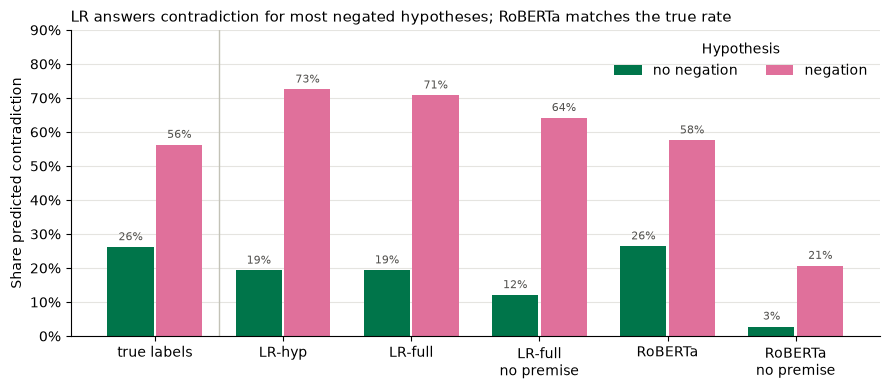

In [97]:
# Share of hypotheses predicted as contradiction, with vs. without negation (validation_matched)
bar_groups = {"true labels": y} | {m: p for m, p in preds["validation_matched"].items() if m != "majority class"}
contra_share = pd.DataFrame({name: {"no negation": (p[~hyp_neg] == CONTRA).mean(),
                                    "negation": (p[hyp_neg] == CONTRA).mean()}
                             for name, p in bar_groups.items()}).T

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(contra_share))
width = 0.38
for i, (group, color) in enumerate([("no negation", "#00754a"), ("negation", "#e0709b")]):
    bars = ax.bar(x + (i - 0.5) * width, contra_share[group], width - 0.02, color=color, label=group)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in contra_share[group]], padding=3, fontsize=8, color="#52514e")
ax.axvline(0.5, color="#c3c2b7", linewidth=1)  # separates the true labels from the models

ax.set_xticks(x, [name.replace(", ", "\n") for name in contra_share.index])
ax.set_ylabel("Share predicted contradiction")
ax.set_ylim(0, 0.9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("LR answers contradiction for most negated hypotheses; RoBERTa matches the true rate",
             loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(title="Hypothesis", frameon=False, loc="upper right", ncol=2)

fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "negation_predicted_contradiction.png"), dpi=200)
plt.show()

**Interpretation.** In the data, 26% of hypotheses without negation and 56% of hypotheses with negation are contradictions (the "true labels" bars).

1. **Logistic regression exaggerates the shortcut.** It answers contradiction for 71–73% of negated hypotheses, even though only 56% of them are contradictions. It has turned "negation often means contradiction" into "negation means contradiction".
2. **RoBERTa matches the true rate** (58% vs. 56%), so it does not over-react to negation.
3. **The traps show the difference most clearly.** On negated hypotheses that are *not* contradictions, LR-full gets only 33% right and wrongly answers contradiction for 49% of them. RoBERTa gets 86% right and answers contradiction for only 7%.
4. **The shortcut pays off on average.** LR is *more* accurate on negated hypotheses (64%) than on the others (54%), because negation usually does mean contradiction. This is why a model learns the shortcut, and why overall accuracy hides the problem: you only see it on the traps.
5. **Without the premise, the difference remains.** LR-full still answers contradiction for 64% of negated hypotheses, RoBERTa for 21%. RoBERTa has learned the cue too, but only as a weak signal.

### What does each model guess without the premise?

Confusion matrices show, for each true label, what the model predicted. We compare each model with and without the premise on `validation_matched`.

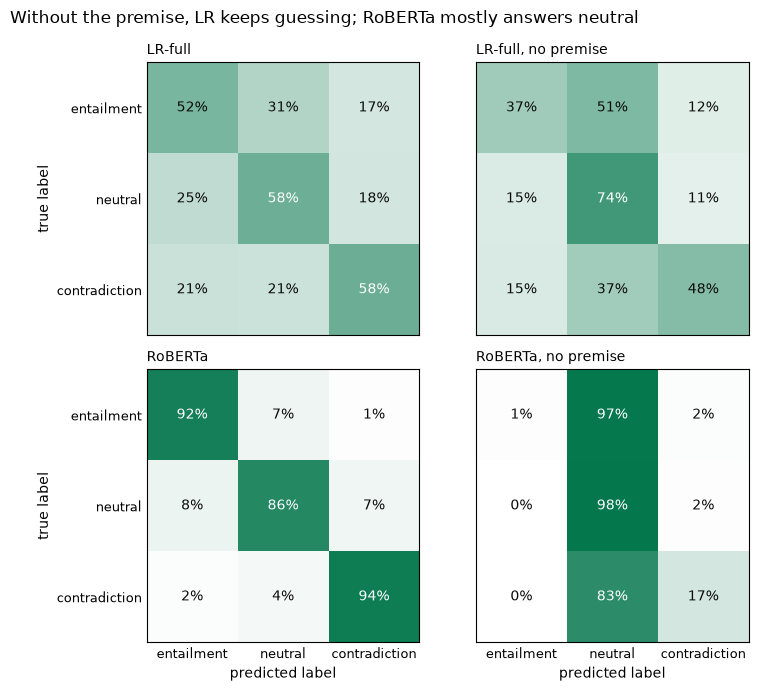

In [ ]:
# Confusion matrices on validation_matched, normalised per true label (each row sums to 100%)
cmap = LinearSegmentedColormap.from_list("white_green", ["#ffffff", "#00754a"])
fig, axes = plt.subplots(2, 2, figsize=(8, 7), sharex=True, sharey=True)
for ax, model in zip(axes.flat, ["LR-full", "LR-full, no premise", "RoBERTa", "RoBERTa, no premise"]):
    cm = confusion_matrix(y, preds["validation_matched"][model], normalize="true")
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=1)
    for i in range(len(LABEL_NAMES)):
        for j in range(len(LABEL_NAMES)):
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=10,
                    color="white" if cm[i, j] > 0.55 else "#0b0b0b")
    ax.set_title(model, fontsize=10, loc="left")
    ax.set_xticks(range(len(LABEL_NAMES)), LABEL_NAMES, fontsize=9)
    ax.set_yticks(range(len(LABEL_NAMES)), LABEL_NAMES, fontsize=9)
    ax.tick_params(length=0)
for ax in axes[1]:
    ax.set_xlabel("predicted label")
for ax in axes[:, 0]:
    ax.set_ylabel("true label")
fig.suptitle("Without the premise, LR keeps guessing; RoBERTa mostly answers neutral", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "confusion_matrices.png"), dpi=200)
plt.show()

**Interpretation.**

**How to read the figure:** each square shows how the examples of one true label (row) were predicted (column). Each row adds up to 100%, and the diagonal from top left to bottom right is the share answered correctly.

- **LR-full** gets 52–58% of each label right, and its mistakes are spread over all labels.
- **LR-full without the premise** looks much the same, with a shift towards neutral. It still finds about half of the contradictions, from hypothesis words alone.
- **RoBERTa** gets 86–94% of each label right. Neutral is the hardest label, since it lies between the other two.
- **RoBERTa without the premise** answers neutral for almost everything. The only exception is contradictions: it still recognises 17% of them, mostly hypotheses with a negation word (see the negation figure above).

### Summary of the results

- **Both models have learned the negation shortcut.** Without the premise, both are much more likely to answer contradiction when the hypothesis contains a negation word.
- **Logistic regression relies on it, and even overuses it.** It barely uses the premise (−3.3 points without it), answers contradiction for 71% of negated hypotheses (true rate 56%), and gets only 33% of the traps right.
- **RoBERTa mostly does not.** It depends heavily on the premise (−53 points without it), predicts contradiction at the true rate, and gets 86% of the traps right. The shortcut only shows up as a weak signal when the premise is missing.

So the answer to the first half of the research question is: the two models *have* learned the same word-level shortcut, but only logistic regression *relies* on it. The SHAP analysis tests whether explanations show the same picture, by looking at which words each model's individual predictions depend on.

## 6. SHAP explanations

Sections 3–5 showed *that* logistic regression relies on the negation shortcut and RoBERTa mostly does not. SHAP shows *which words* each individual prediction depends on.

**The idea in short:** for one example, we delete different combinations of words and see how the model's probability for its predicted label changes. A word that raises the probability when it is present gets a positive SHAP value, a word that lowers it gets a negative value, and an unimportant word gets a value close to zero. We use the same method (KernelSHAP over words) for both models, so differences in the explanations come from the models and not from the explanation method (Lundberg & Lee, 2017).

The RoBERTa part runs the model 150,000 times on short inputs. We expect it to take roughly 10–30 minutes on a T4, but this is an estimate.

### The sample

SHAP is slow, so we explain a sample of 300 examples from `validation_matched`: 50 for each combination of label and negation. That way half the sample has a negation word in the hypothesis, and among those are 100 traps (negated entailments and neutrals). We only use examples with at most 40 words in total, since the explanations get unreliable for very long inputs. This keeps about 80% of the examples. The sample is drawn with a fixed seed, so it is the same on Colab and locally.

In [99]:
SHAP_PER_GROUP = 50   # examples per (label, negation) group: 3 labels x 2 = 300 examples
SHAP_MAX_WORDS = 40   # premise + hypothesis words; KernelSHAP gets unreliable for long inputs
SHAP_NSAMPLES = 500   # masked versions of each example the explainer evaluates

def split_words(text):
    # Split on whitespace, so joining the kept words with spaces rebuilds the original text
    return text.split()

n_words = val_df.premise.map(lambda t: len(split_words(t))) + val_df.hypothesis.map(lambda t: len(split_words(t)))
candidates = val_df[n_words <= SHAP_MAX_WORDS]
shap_sample = candidates.groupby(["label", "hyp_neg"]).sample(SHAP_PER_GROUP, random_state=SEED)
print(f"{len(candidates):,} of {len(val_df):,} examples have at most {SHAP_MAX_WORDS} words; sampled {len(shap_sample)}")
pd.crosstab(shap_sample.label.map(dict(enumerate(LABEL_NAMES))),
            shap_sample.hyp_neg.map({False: "no negation", True: "negation"}))

7,883 of 9,815 examples have at most 40 words; sampled 300


hyp_neg,negation,no negation
label,,
contradiction,50,50
entailment,50,50
neutral,50,50


### How one prediction is explained

For each example and model:

1. Split the premise and hypothesis into words. Premise words and hypothesis words are separate features, so "not" in the premise and "not" in the hypothesis are different features.
2. Find the label the model predicts for the full input. We explain the model's probability for *that* label.
3. KernelSHAP creates 500 versions of the example with different words deleted, runs the model on each, and estimates from the results how much each word contributes. The starting point (baseline) is the input with all words deleted.

The SHAP values of all words add up to: (probability with all words) − (probability with no words). The same procedure is used for both models, only the function that runs the model differs.

In [100]:
import pickle

import shap
from tqdm.auto import tqdm

def masked_texts(premise_words, hypothesis_words, masks):
    # Each row of masks says which words to keep (1) or delete (0); premise words come first
    n_p = len(premise_words)
    premises = [" ".join(w for w, keep in zip(premise_words, m[:n_p]) if keep) for m in masks]
    hypotheses = [" ".join(w for w, keep in zip(hypothesis_words, m[n_p:]) if keep) for m in masks]
    return premises, hypotheses

def explain(prob_fn, premise, hypothesis):
    # prob_fn(premises, hypotheses) returns class probabilities in LABEL_NAMES order.
    # We explain the probability of the label the model predicts for the full input.
    p_words, h_words = split_words(premise), split_words(hypothesis)
    n = len(p_words) + len(h_words)
    pred = int(prob_fn([premise], [hypothesis])[0].argmax())
    f = lambda masks: prob_fn(*masked_texts(p_words, h_words, masks))[:, pred]
    explainer = shap.KernelExplainer(f, np.zeros((1, n)))  # baseline: all words deleted
    values = explainer.shap_values(np.ones((1, n)), nsamples=SHAP_NSAMPLES, silent=True)
    return {"premise_words": p_words, "hypothesis_words": h_words, "pred": pred,
            "shap": np.ravel(values), "base_value": float(np.ravel(explainer.expected_value)[0])}

def shap_or_load(name, prob_fn):
    path = os.path.join(RESULTS_DIR, f"shap_{name}.pkl")
    if os.path.exists(path):
        print(f"shap_{name}: loaded from {path}")
        results = pickle.load(open(path, "rb"))
    else:
        print(f"shap_{name}: explaining {len(shap_sample)} examples")
        results = [{"idx": idx, **explain(prob_fn, p, h)}
                   for idx, p, h in tqdm(list(zip(shap_sample.index, shap_sample.premise, shap_sample.hypothesis)))]
        pickle.dump(results, open(path, "wb"))
    # The sample is drawn with a fixed seed, so a cached file must belong to the same sample
    assert [r["idx"] for r in results] == list(shap_sample.index), f"{path} is from another sample: delete it"
    return results

### Logistic regression

In [101]:
def lr_probs(premises, hypotheses):
    return lr_full.predict_proba(featurize(pd.DataFrame({"premise": premises, "hypothesis": hypotheses})))

shap_lr = shap_or_load("lr", lr_probs)

shap_lr: loaded from results\shap_lr.pkl


### RoBERTa

In [102]:
def roberta_probs(premises, hypotheses):
    logits = roberta_logits(premises, hypotheses, progress=False)
    return torch.softmax(torch.from_numpy(logits), dim=1).numpy()

shap_roberta = shap_or_load("roberta", roberta_probs)

shap_roberta: loaded from results\shap_roberta.pkl


### A first look: one trap example

A trap from the sample where LR answers contradiction (following the negation shortcut) and RoBERTa gives the right answer. For each word, the table shows how much it pushed each model towards the label *that model* predicted: positive values push towards it, negative values away from it. The full comparison over all 300 examples comes in the next section.

In [127]:
def shap_table(i):
    # The words of sample example i, with each model's SHAP value towards the label that model predicts
    r_lr, r_rb = shap_lr[i], shap_roberta[i]
    # print actual text
    print(f"Premise: {val_df.premise[r_lr['idx']]}")
    print(f"Hypothesis: {val_df.hypothesis[r_lr['idx']]}")
    print(f"True label: {LABEL_NAMES[val_df.label[r_lr['idx']]]}.  "
          f"LR predicts {LABEL_NAMES[r_lr['pred']]}, RoBERTa predicts {LABEL_NAMES[r_rb['pred']]}.")
    n_p = len(r_lr["premise_words"])
    # Premise and hypothesis side by side; the shorter one is padded with blanks
    fmt = lambda values: [f"{v:.3f}" for v in values]
    sides = {part: pd.DataFrame({"word": words, "LR": fmt(r_lr["shap"][span]), "RoBERTa": fmt(r_rb["shap"][span])})
             for part, words, span in [("premise", r_lr["premise_words"], slice(None, n_p)),
                                       ("hypothesis", r_lr["hypothesis_words"], slice(n_p, None))]}
    return pd.concat(sides, axis=1).fillna("")

# First trap in the sample where LR falls for the negation shortcut and RoBERTa gets it right
trap = next(i for i, (r_lr, r_rb) in enumerate(zip(shap_lr, shap_roberta))
            if val_df.hyp_neg[r_lr["idx"]] and r_lr["pred"] == CONTRA
            and r_rb["pred"] == val_df.label[r_lr["idx"]] != CONTRA)
shap_table(trap)

Premise: Yes, undoubtedly the hand of Mr. Brown! Mr. Carter paused.
Hypothesis: There is no doubt that hand belongs to Mr. Brown.
True label: entailment.  LR predicts contradiction, RoBERTa predicts entailment.


premise                 hypothesis                
          word      LR RoBERTa       word      LR RoBERTa
0         Yes,  -0.069   0.000      There  -0.068   0.000
1  undoubtedly   0.000   0.153         is   0.080  -0.039
2          the   0.000   0.000         no   0.578   0.000
3         hand   0.000   0.155      doubt   0.000   0.059
4           of   0.037   0.000       that  -0.069   0.000
5          Mr.   0.000  -0.056       hand   0.000  -0.036
6       Brown!   0.000   0.277    belongs  -0.051  -0.058
7          Mr.   0.000   0.000         to  -0.078   0.000
8       Carter   0.034   0.000        Mr.   0.029  -0.070
9      paused.   0.000   0.000     Brown.   0.000  -0.100

## 7. Comparing the explanations

We compare the SHAP explanations of the two models over all 300 examples in the sample, in two ways:

1. **Premise share:** how much of each explanation is on the premise?
2. **Most important words overall:** which words matter most on average?

**Note on zeros.** shap 0.54 keeps only the 10 most important words per example (the default `l1_reg="num_features(10)"`) and gives every other word exactly 0. Examples with more than 10 words therefore have zeros, as in the trap table above. Both measures below therefore only use each example's top 10 words.

In [128]:
MODEL_COLORS = {"LR": "#e0709b", "RoBERTa": "#00754a"}

rows = []
for r_lr, r_rb in zip(shap_lr, shap_roberta):
    n_p = len(r_lr["premise_words"])  # premise words come first
    row = {"idx": r_lr["idx"], "label": val_df.label[r_lr["idx"]]}
    for model, r in [("LR", r_lr), ("RoBERTa", r_rb)]:
        s = np.abs(r["shap"])
        row[f"{model} pred"] = r["pred"]
        row[f"{model} premise share"] = s[:n_p].sum() / s.sum()
    rows.append(row)
shap_compare = pd.DataFrame(rows)

for model in MODEL_COLORS:
    print(f"{model} accuracy on the sample: {(shap_compare[f'{model} pred'] == shap_compare.label).mean():.0%}")

LR accuracy on the sample: 52%
RoBERTa accuracy on the sample: 92%


### Premise share

The share of each explanation that is on the premise: the sum of |SHAP| over premise words divided by the sum over all words. Section 5 showed that RoBERTa needs the premise and LR barely does, so we expect a clearly higher premise share for RoBERTa.

          LR  RoBERTa
mean    0.17     0.37
median  0.14     0.36
RoBERTa has the higher premise share in 77% of examples


C:\Users\Malin Haugland Høli\AppData\Local\Temp\ipykernel_27268\2751002926.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = ax.boxplot([share[m] for m in MODEL_COLORS], vert=False, widths=0.5, patch_artist=True,


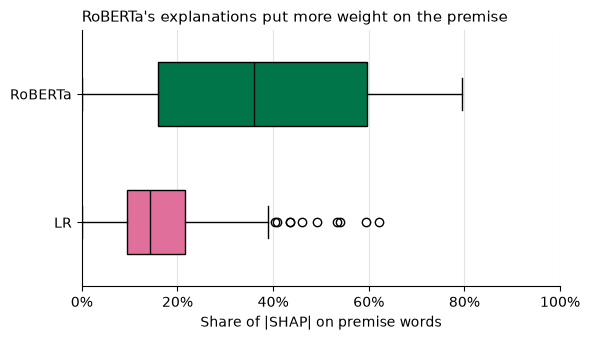

In [46]:
share = shap_compare[[f"{m} premise share" for m in MODEL_COLORS]]
share.columns = list(MODEL_COLORS)
print(share.describe().loc[["mean", "50%"]].rename(index={"50%": "median"}).round(2).to_string())
print(f"RoBERTa has the higher premise share in {(share.RoBERTa > share.LR).mean():.0%} of examples")

fig, ax = plt.subplots(figsize=(6, 3.5))
box = ax.boxplot([share[m] for m in MODEL_COLORS], vert=False, widths=0.5, patch_artist=True,
                 medianprops={"color": "#0b0b0b"})
for patch, color in zip(box["boxes"], MODEL_COLORS.values()):
    patch.set_facecolor(color)
ax.set_yticks([1, 2], list(MODEL_COLORS))
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of |SHAP| on premise words")
ax.set_title("RoBERTa's explanations put more weight on the premise", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "shap_premise_share.png"), dpi=200)
plt.show()

**Interpretation.** The explanations agree with the premise ablation in section 5. LR puts a median of 14% of its explanation on the premise, and RoBERTa 36%. RoBERTa has the higher share in 77% of the examples. Premises are about twice as long as hypotheses, so both models still focus mostly on the hypothesis, but RoBERTa's explanations spread much more widely: from almost nothing to 80% on the premise, depending on the example.

### Most important words overall

The mean |SHAP| of each word across the sample, for each model. Words are lowercased with punctuation removed, and premise and hypothesis words are kept apart (`P:` and `H:`). We only show words that occur at least 5 times in the sample, since a mean over one or two occurrences is mostly noise.

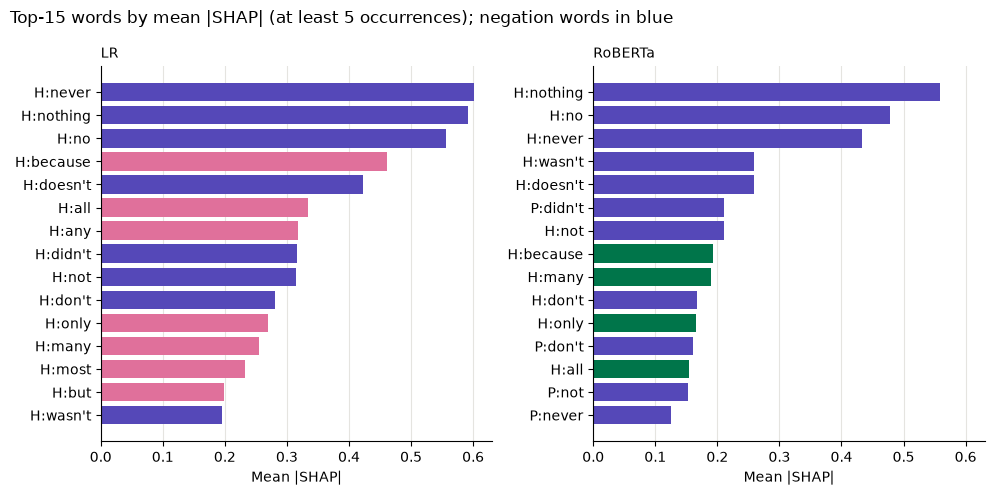

11 of 15 words are in both lists: H:all, H:because, H:doesn't, H:don't, H:many, H:never, H:no, H:not, H:nothing, H:only, H:wasn't


In [131]:
MIN_COUNT = 5

def global_importance(results):
    values = {}
    for r in results:
        n_p = len(r["premise_words"])
        for i, (w, v) in enumerate(zip(r["premise_words"] + r["hypothesis_words"], r["shap"])):
            word = w.lower().strip(".,!?;:\"()")
            if word:
                values.setdefault(("P:" if i < n_p else "H:") + word, []).append(abs(v))
    return pd.DataFrame({"mean |SHAP|": {w: np.mean(v) for w, v in values.items()},
                         "count": {w: len(v) for w, v in values.items()}})

importance = {"LR": global_importance(shap_lr), "RoBERTa": global_importance(shap_roberta)}
top15 = {m: imp[imp["count"] >= MIN_COUNT].sort_values("mean |SHAP|", ascending=False).head(15)
         for m, imp in importance.items()}

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True)
for ax, (model, top) in zip(axes, top15.items()):
    words = top.index[::-1]
    colors = ["#5548b8" if has_negation(w[2:]) else MODEL_COLORS[model] for w in words]
    ax.barh(words, top["mean |SHAP|"][::-1], color=colors)
    ax.set_title(model, loc="left", fontsize=10)
    ax.set_xlabel("Mean |SHAP|")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle(f"Top-15 words by mean |SHAP| (at least {MIN_COUNT} occurrences); negation words in blue", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "shap_top_words.png"), dpi=200)
plt.show()

overlap = set(top15["LR"].index) & set(top15["RoBERTa"].index)
print(f"{len(overlap)} of 15 words are in both lists: {', '.join(sorted(overlap))}")

**Interpretation.** Averaged over the whole sample, the two lists look surprisingly alike: 11 of 15 words are shared, and the strong negation words *never, nothing, no* are at the top for both. Two things differ:

- RoBERTa's list includes **premise negation** (`P:didn't`, `P:don't`, `P:not`, `P:never`). It notices when the premise is itself negated, which is needed to judge whether a negated hypothesis follows. All 15 of LR's words are hypothesis words.
- LR gives more weight to hypothesis cues without negation: *any, most* and *but* are only in its list.

The global ranking hides the main finding from section 5. Mean |SHAP| mixes contradictions, where negation is the right word to focus on, with traps, where it is a shortcut. So similar global word lists do **not** mean that the models use those words in the same way. This is a reason to compare explanations per example and per group, not only globally.

### Summary of the explanation comparison

- **The explanations confirm the behavioural results from section 5.** LR's explanations sit almost entirely on the hypothesis (median 14% on the premise), while RoBERTa's put clearly more weight on the premise (median 36%).
- **Globally the models look alike** (both rank *never, nothing, no* highest), because both treat negation as important in real contradictions. Only the traps in section 5 show that LR also follows negation where it misleads.

So for the second half of the research question: yes, SHAP shows negation words driving both models. Together with the trap results from section 5 and the examples in section 8, it shows that only LR also lets them drive wrong answers. Global word rankings alone would have suggested more agreement than there is.

**Limitations.** Each explanation keeps only the 10 most important words; KernelSHAP with 500 samples is an estimate and can be noisy for small values; and the 300 examples were drawn to contain 50% negated hypotheses, so overall rates in the sample do not match the full validation set.

## 8. Qualitative examples

Four examples from the SHAP sample that show the patterns from section 7 in single predictions. Each plot shows every word's SHAP value towards the label *that model* predicts: coloured bars push towards it, grey bars away from it. Premise words are above the line, hypothesis words below it.

1. **Negation in both sentences:** LR answers contradiction because of *didn't*; RoBERTa answers entailment and relies on the *not* in the premise.
2. **Both models fall for the shortcut:** a neutral hypothesis with *not* that both models call a contradiction.
3. **A contradiction without negation (antonyms):** both are right, but only RoBERTa uses the premise word *hot*.
4. **A contradiction without negation (quantifiers):** both rely on *All*, but RoBERTa also uses *Some* in the premise.

1. Negation in both sentences (true label: entailment)
   Premise:    The door did not budge.
   Hypothesis: The door didn't move. 
2. Both models fall for the shortcut (true label: neutral)
   Premise:    In 1979, he stopped at a Lexington clothing store to buy cowboy boots.
   Hypothesis: There were not cowboy boots at the store.
3. Contradiction through antonyms (true label: contradiction)
   Premise:    It was going to be a hot day. 
   Hypothesis: It was a very cold day.
4. Contradiction through quantifiers (true label: contradiction)
   Premise:    Some rooms have balconies.
   Hypothesis: All of the rooms have balconies off of them.


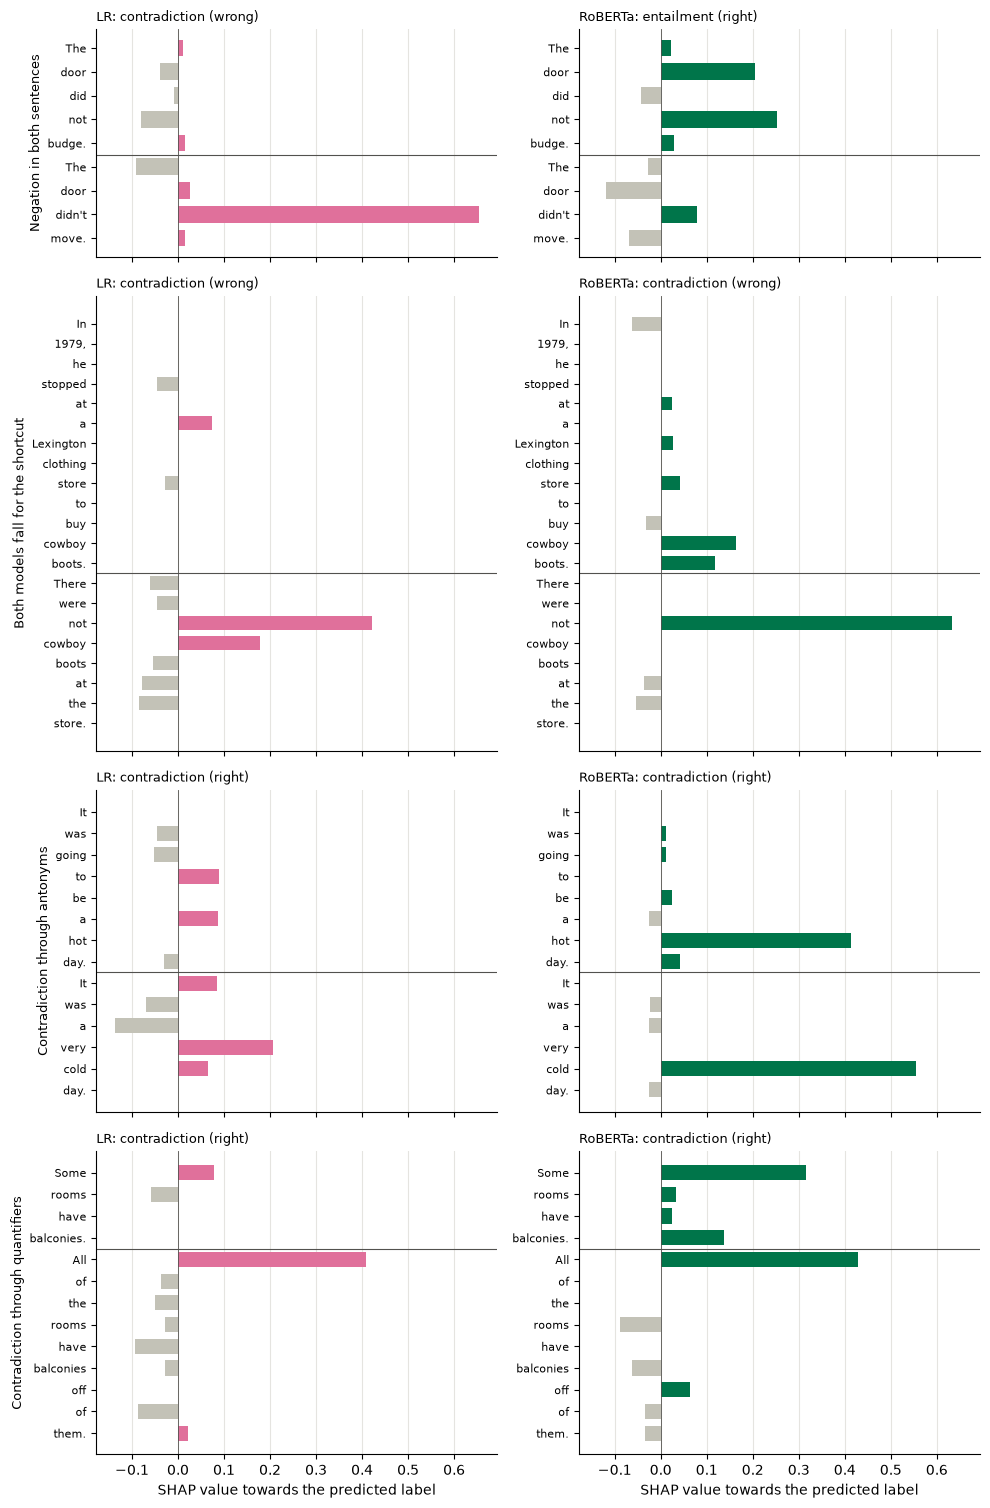

In [132]:
# Validation indices of the examples, in the order of the list above
QUALITATIVE = [(9536, "Negation in both sentences"),
               (2119, "Both models fall for the shortcut"),
               (5839, "Contradiction through antonyms"),
               (3650, "Contradiction through quantifiers")]
position = {r["idx"]: j for j, r in enumerate(shap_lr)}

def plot_example(ax_pair, idx, title):
    r_lr, r_rb = shap_lr[position[idx]], shap_roberta[position[idx]]
    n_p = len(r_lr["premise_words"])
    words = r_lr["premise_words"] + r_lr["hypothesis_words"]
    y = np.arange(len(words))
    for ax, (model, r) in zip(ax_pair, [("LR", r_lr), ("RoBERTa", r_rb)]):
        colors = [MODEL_COLORS[model] if v > 0 else "#c3c2b7" for v in r["shap"]]
        ax.barh(y, r["shap"], color=colors, height=0.7)
        ax.axhline(n_p - 0.5, color="#52514e", linewidth=0.8)  # premise above, hypothesis below
        ax.axvline(0, color="#52514e", linewidth=0.6)
        ax.set_yticks(y, words, fontsize=8)
        ax.invert_yaxis()
        ok = "right" if r["pred"] == val_df.label[idx] else "wrong"
        ax.set_title(f"{model}: {LABEL_NAMES[r['pred']]} ({ok})", loc="left", fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
        ax.set_axisbelow(True)
    ax_pair[0].set_ylabel(title, fontsize=9)

for n, (idx, title) in enumerate(QUALITATIVE, 1):
    print(f"{n}. {title} (true label: {LABEL_NAMES[val_df.label[idx]]})")
    print(f"   Premise:    {val_df.premise[idx]}")
    print(f"   Hypothesis: {val_df.hypothesis[idx]}")

heights = [len(shap_lr[position[idx]]["shap"]) + 3 for idx, _ in QUALITATIVE]
fig, axes = plt.subplots(len(QUALITATIVE), 2, figsize=(10, sum(heights) * 0.22), sharex=True,
                         gridspec_kw={"height_ratios": heights})
for ax_pair, (idx, title) in zip(axes, QUALITATIVE):
    plot_example(ax_pair, idx, title)
for ax in axes[-1]:
    ax.set_xlabel("SHAP value towards the predicted label")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "shap_qualitative_examples.png"), dpi=200)
plt.show()

**Interpretation.**

1. **Negation in both sentences** (*The door did not budge.* → *The door didn't move.*, entailment). LR puts almost all its weight on the hypothesis word *didn't* (+0.65) and answers contradiction. It cannot see that the premise is negated too. RoBERTa answers entailment, and its two largest values are on the premise: *not* (+0.25) and *door* (+0.21). This is the premise negation from the global word lists in section 7, at work in one example.
2. **Both models fall for the shortcut** (*In 1979, he stopped at a Lexington clothing store to buy cowboy boots.* → *There were not cowboy boots at the store.*, neutral). Both answer contradiction, and for both *not* is by far the most important word (LR +0.42, RoBERTa +0.63). RoBERTa also gives positive values to *cowboy boots* in the premise, so it relates the two sentences, but it reads "went to buy boots" as "the store had boots". This is one of only 4 traps in the sample that RoBERTa gets wrong.
3. **Antonyms** (*It was going to be a hot day.* → *It was a very cold day.*, contradiction). Both are right, for different reasons. RoBERTa relies on the antonym pair *hot* (+0.41) and *cold* (+0.55). LR's top word is *very* (+0.21), a general contradiction cue, and it gives *hot* exactly 0: it has no feature that connects *hot* in the premise with *cold* in the hypothesis (see section 3).
4. **Quantifiers** (*Some rooms have balconies.* → *All of the rooms have balconies off of them.*, contradiction). Both models rely most on *All*, the quantifier cue from the EDA. RoBERTa also gives a large value to *Some* in the premise (+0.32, against +0.08 for LR), so its answer depends on the contrast between the two quantifiers.

When the hypothesis alone settles the label, the two models look alike. When the answer depends on the premise, RoBERTa's explanations point to the relevant premise words and LR's do not.